## **Exercise 1: Continuous Bag of Words (CBOW) Model**

CBOW predicts a target word given its surrounding context words. It averages the context word vectors to predict the target word.

### Mathematical Formulation

The CBOW (Continuous Bag of Words) model is designed to predict a target word $w_t$ given its surrounding context words. The model maximizes the following objective function:

$$
\mathcal{L} = \frac{1}{T} \sum_{t=1}^{T} \log p(w_t | w_{t-c}, \ldots, w_{t-1}, w_{t+1}, \ldots, w_{t+c})
$$

Here:
- $T$ is the total number of target words in the corpus.
- $c$ is the size of the context window.

### Probability Computation with Softmax

The conditional probability $p(w_t | \text{context})$ is modeled using the **softmax function**, which ensures the probabilities sum to 1 over all vocabulary words:

$$
p(w_t | \text{context}) = \frac{\exp(\mathbf{v}_{w_t}^{\top} \hat{\mathbf{h}})}{\sum_{w=1}^{|V|} \exp(\mathbf{v}_w^{\top} \hat{\mathbf{h}})}
$$

- $\mathbf{v}_{w_t}$ is the output embedding (vector representation) for the target word $w_t$.
- $\hat{\mathbf{h}}$ is the averaged context vector, computed as:

$$
\hat{\mathbf{h}} = \frac{1}{2c} \sum_{\substack{-c \leq j \leq c \\ j \neq 0}} \mathbf{v}_{w_{t+j}}
$$

- $\mathbf{v}_{w_{t+j}}$ is the embedding vector of a context word $w_{t+j}$.
- $|V|$ is the size of the vocabulary, meaning the denominator sums over all possible words.

### Why Multiply Vectors?

In the numerator of the softmax, $\mathbf{v}_{w_t}^{\top} \hat{\mathbf{h}}$ is the dot product between:
1. The target word vector ($\mathbf{v}_{w_t}$), representing the model's prediction for $w_t$.
2. The context vector ($\hat{\mathbf{h}}$), which captures information about the surrounding context.

This dot product measures how closely aligned the target word vector is with the context vector. Larger values indicate a better fit, resulting in higher probabilities after applying the softmax.

The softmax itself ensures that these scores are normalized into valid probabilities.

### Example

Consider the sentence: **"The quick brown fox jumps over the lazy dog"** with a context window size of $c=2$.

The context words and target word for the target word "brown" are:

```python
context_words = ["The", "quick", "fox", "jumps"]
target_word = "brown"
# The model learns to maximize p(target_word | context_words)
```


**Task:**

**Task 1: Data Preprocessing**  
Implement `preprocess_corpus(corpus)` to tokenize the text, convert it to sequences of indices, and build the vocabulary.  

**Task 2: CBOW Pairs**  
Write `generate_cbow_pairs(sequences, window_size)` to generate (context, target) pairs from tokenized sequences.  

**Task 3: Model Architecture**  
- Create `create_cbow_model(vocab_size, window_size, embedding_dim)` using `Embedding` and `Dense` layers.  
- Use `print_model_architecture(model, input_shape)` to display the model summary.

**Task 4: Training**  
Train the CBOW model on the corpus using a window size of 2 and embedding dimension of 20.

**Task 5: Embedding Visualization**  
Use `plot_word_embeddings(model, tokenizer)` to visualize word embeddings using PCA.

**Task 6: Find Similar Words**  
Implement `find_similar_words(word, tokenizer, model, top_n=3)` to find top-n similar words using cosine similarity.  
Test the function for words: `"cat"`, `"dog"`, `"love"`, `"people"`, `"toy"`, `"the"`.



In [1]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, Lambda, Flatten
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping


def preprocess_corpus(corpus):
    """
    Tokenize and preprocess the corpus into sequences of word indices.

    Args:
        corpus (list of str): A list of sentences (text corpus), where each sentence is a string.
            Example:
                ["The cat plays with the toy.", "The dog plays with the toy."]

    Returns:
        tokenizer (Tokenizer object imported from tensorflow.keras.preprocessing.text): Fitted tokenizer containing word-index mappings (vocab).
        sequences (list of list of int): A list of tokenized sentences, where each word in a sentence is represented by its index (using vocab word-index mappings).
            Example: [[1, 2, 3, 4, 5], [1, 6, 3, 4, 5]]
        vocab_size (int): The total number of unique words in the corpus, plus one for padding (we add pad token to make all sents have the same size).

    Example:
        input:    corpus = ["the cat plays with the toy", "The dog plays"]
        output:   Index to Word: {1: 'the', 2: 'plays', 3: 'cat', 4: 'with', 5: 'toy', 6: 'dog'}
                  sequences: [[1, 3, 2, 4, 1, 5], [1, 6, 2]]
                  vocab_size: 7
    """
    tokenizer = Tokenizer()
    tokenizer.fit_on_texts(corpus)
    sequences = tokenizer.texts_to_sequences(corpus)
    vocab_size = len(tokenizer.word_index) + 1
    return tokenizer, sequences, vocab_size

# # Testing Tokenizer on toy example
example_sents = ["the cat plays with the toy", "The dog plays"]
tokenizer, sequences, vocab_size = preprocess_corpus(example_sents)

print("Index to Word:",tokenizer.index_word)
print("Sequences:",sequences)
print("Vocab size:",vocab_size)



Index to Word: {1: 'the', 2: 'plays', 3: 'cat', 4: 'with', 5: 'toy', 6: 'dog'}
Sequences: [[1, 3, 2, 4, 1, 5], [1, 6, 2]]
Vocab size: 7


In [2]:
def generate_cbow_pairs(sequences, window_size):
    """
    Generate context-target pairs for the Continuous Bag of Words (CBOW) model.

    Args:
        sequences (list of list of int): List of tokenized sentences, where each sentence is represented as a sequence of word indices.
            Example: [[1, 3, 2, 4, 1, 5], [1, 6, 2]]
        window_size (int): The context window size, i.e., how many words to consider around each target word.
            Example: for window of size 2 [first left word, second left word, first right word, second right word]

    Returns:
        contexts (ndarray): A 2D numpy array for all words of all sents (word by word) where each row contains the context words for a target word, padded to the window size.
            Shape: (num_pairs, 2 * window_size)

        targets (ndarray): A 1D numpy array of target word indices corresponding to each context.
            Shape: (num_pairs,)

    Full Example:
    --------------------------------------------------------------------------
        Input to the generate_cbow_pairs function:
        sentences = ["the cat plays with the toy", "The dog plays"]
        window_size = 2

    --------------------------------------------------------------------------
        Expected output of generate_cbow_pairs function:
        - It will generate context of shape (9,4) 9 being the number of words in all sents (in our case 6 + 3)
            and 4 is context size * 2
        - It will generate a targets of shape (9), which is the number of contexts (or words/ context for each word)

      Contexts: [
                    [0 0 3 2]
                    [1 0 2 4]
                    [1 3 4 1]
                    [3 2 1 5]
                    [2 4 5 0]
                    [4 1 0 0]
                    [0 0 6 2]
                    [1 0 2 0]
                    [1 6 0 0]
               ]


      Targets: [1 3 2 4 1 5 1 6 2]

        Explanation:----------------------------------------

      Word at pos: 0:
        Target word: the
        Context words: ['PADDING', 'PADDING', 'cat', 'plays']

      Word at pos: 1:
        Target word: cat
        Context words: ['the', 'PADDING', 'plays', 'with']

      Word at pos: 2:
        Target word: plays
        Context words: ['the', 'cat', 'with', 'the']

      Word at pos: 3:
        Target word: with
        Context words: ['cat', 'plays', 'the', 'toy']

      Word at pos: 4:
        Target word: the
        Context words: ['plays', 'with', 'toy', 'PADDING']

      Word at pos: 5:
        Target word: toy
        Context words: ['with', 'the', 'PADDING', 'PADDING']

      Word at pos: 6:
        Target word: the
        Context words: ['PADDING', 'PADDING', 'dog', 'plays']

      Word at pos: 7:
        Target word: dog
        Context words: ['the', 'PADDING', 'plays', 'PADDING']

      Word at pos: 8:
        Target word: plays
        Context words: ['the', 'dog', 'PADDING', 'PADDING']
    """
    contexts = []
    targets = []
    
    for seq in sequences:
        for i in range(len(seq)):
            context = []
            # Left context
            for j in range(window_size, 0, -1):
                context.append(seq[i-j] if i-j >= 0 else 0)
            # Right context
            for j in range(1, window_size + 1):
                context.append(seq[i+j] if i+j < len(seq) else 0)
            
            contexts.append(context)
            targets.append(seq[i])
    
    return np.array(contexts), np.array(targets)


# # Example corpus of sentences
example_sents = ["the cat plays with the toy", "The dog plays"]
tokenizer, sequences, vocab_size = preprocess_corpus(example_sents)

# # Print the tokenizer details
print("Index to Word:", tokenizer.index_word)
print("Sequences:", sequences)
print("Vocab size:", vocab_size)

# # Generate CBOW pairs for context and target
contexts, targets = generate_cbow_pairs(sequences, window_size=2)

# # Flatten the list of sentences into a single list of words and sequences
flat_sents = [word for sent in example_sents for word in sent.split()]
flat_seqs = [word for seq in sequences for word in seq]

# # Print the context and target words for each sentence
print("\n\nContexts:",contexts.shape, contexts)
print("\n\nTargets:",targets.shape, targets)

# # Output the context and target words for each word in the flattened lists
for index, (word, seq, context, target) in enumerate(zip(flat_sents, flat_seqs, contexts, targets)):
    print(f"\n Word at pos: {index}:")
    print(f"  Target word: {tokenizer.index_word.get(target, 'PADDING')}")
    print(f"  Context words: {[tokenizer.index_word.get(word, 'PADDING') for word in context]}")

Index to Word: {1: 'the', 2: 'plays', 3: 'cat', 4: 'with', 5: 'toy', 6: 'dog'}
Sequences: [[1, 3, 2, 4, 1, 5], [1, 6, 2]]
Vocab size: 7


Contexts: (9, 4) [[0 0 3 2]
 [0 1 2 4]
 [1 3 4 1]
 [3 2 1 5]
 [2 4 5 0]
 [4 1 0 0]
 [0 0 6 2]
 [0 1 2 0]
 [1 6 0 0]]


Targets: (9,) [1 3 2 4 1 5 1 6 2]

 Word at pos: 0:
  Target word: the
  Context words: ['PADDING', 'PADDING', 'cat', 'plays']

 Word at pos: 1:
  Target word: cat
  Context words: ['PADDING', 'the', 'plays', 'with']

 Word at pos: 2:
  Target word: plays
  Context words: ['the', 'cat', 'with', 'the']

 Word at pos: 3:
  Target word: with
  Context words: ['cat', 'plays', 'the', 'toy']

 Word at pos: 4:
  Target word: the
  Context words: ['plays', 'with', 'toy', 'PADDING']

 Word at pos: 5:
  Target word: toy
  Context words: ['with', 'the', 'PADDING', 'PADDING']

 Word at pos: 6:
  Target word: the
  Context words: ['PADDING', 'PADDING', 'dog', 'plays']

 Word at pos: 7:
  Target word: dog
  Context words: ['PADDING', 'the', 'plays

In [3]:
def create_cbow_model(vocab_size, window_size, embedding_dim):
    """
    Create CBOW model using Sequential API.

    Args:
        vocab_size (int): The size of the vocabulary (number of unique words in the corpus).
        window_size (int): The size of the context window (i.e., how many words on each side of the target word to consider).
        embedding_dim (int): The dimensionality of the word embeddings (the size of each embedding vector).

    Returns:
        model (tensorflow.keras.Model): A compiled Keras model for the CBOW task.
    """
    # Initialize a Sequential model, which allows us to build it layer-by-layer.
    model = Sequential([
        # 1. Embedding Layer:
        # This layer takes in the word indices (context words) and looks up their corresponding embedding vectors.
        # The size of the output vectors is determined by `embedding_dim`.
        # `input_length=2 * window_size`: The length of the input context, which is 2 * window_size because we have context words on both sides of the target word.
        # Embedding(..., name="Word_Embedding"),
        Embedding(vocab_size, embedding_dim, input_length=2*window_size, name="Word_Embedding"),
        # 2. Lambda Layer (Mean Pooling):
        # The context consists of multiple words. We want to reduce this to a single vector that represents the context.
        # To do this, we compute the mean (average) of the embeddings of all context words.
        # `axis=1` means the mean is calculated over the context words, which are represented by the first axis in the output of the embedding layer.
        # Lambda(..., name="Mean_Pooling"),
        Lambda(lambda x: tf.reduce_mean(x, axis=1), name="Mean_Pooling"),
        # 3. Dense Layer (Output Layer):
        # This layer will predict the target word given the pooled context representation.
        # The output is a probability distribution over the entire vocabulary, hence we use the `softmax` activation function.
        # The output size is `vocab_size`, which corresponds to the number of possible target words.
        # Dense(..., activation='softmax', name="Softmax_Output")
        Dense(vocab_size, activation='softmax', name="Softmax_Output")
    ])

    # Compile the model with Adam optimizer and categorical cross-entropy loss.
    # The Adam optimizer is efficient for training deep learning models, and categorical cross-entropy is appropriate for multi-class classification.
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    # Return the compiled model
    return model

def print_model_architecture(model, input_shape):
    """Print the model architecture (layers, names, and shapes)."""
    # Build the model by providing an example input shape (batch size, sequence length).
    model.build(input_shape)

    # Print model summary to see the details about each layer and its output shapes.
    print("\nModel Architecture:")
    print("=" * 40)
    model.summary()  # This prints out the architecture of the model (layer by layer).
    print("=" * 40)


window_size = 2
vocab_size=7
embedding_dim=20
model = create_cbow_model(vocab_size=vocab_size, window_size=window_size, embedding_dim=embedding_dim)
print_model_architecture(model, input_shape=(None, 2 * window_size))

c:\Users\Rosey\anaconda3\envs\NLP\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(




Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Word_Embedding (Embedding)      │ (None, 4, 20)          │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Mean_Pooling (Lambda)           │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Softmax_Output (Dense)          │ (None, 7)              │           147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 287 (1.12 KB)

 Trainable params: 287 (1.12 KB)

 Non-trainable params: 0 (0.00 B)


Model Architecture:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Word_Embedding (Embedding)      │ (None, 4, 20)          │           440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Mean_Pooling (Lambda)           │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Softmax_Output (Dense)          │ (None, 22)             │           462 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 902 (3.52 KB)

 Trainable params: 902 (3.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0690 - loss: 3.0890     
Epoch 2/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1379 - loss: 3.0669   
Epoch 3/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1379 - loss: 3.0437   
Epoch 4/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1494 - loss: 3.0149   
Epoch 5/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1724 - loss: 2.9791 
Epoch 6/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1724 - loss: 2.9366
Epoch 7/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1724 - loss: 2.8886   
Epoch 8/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1724 - loss: 2.8354   
Epoch 9/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1724 - loss: 2.7784   
Epoch 10/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1724 - loss: 2.7199
Epoch 11/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1724 - loss: 2.6627
Epoch 12/200
44/44 ━━━━━━━━━━━━━━━━━━━━

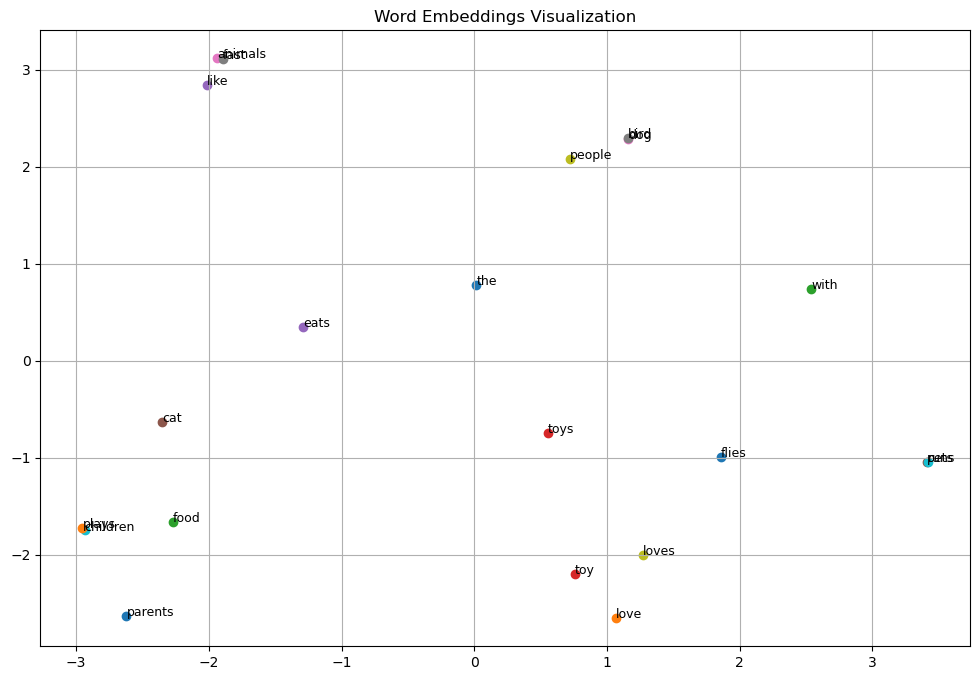

In [4]:

def train_model(model, contexts, targets, epochs=300, batch_size=8):
    """Train the CBOW model"""

    # EarlyStopping monitors the loss during training and stops training if the loss stops improving.
    early_stopping = EarlyStopping(monitor='loss',
                                 patience=20,
                                 min_delta=0.0001)

    # Train the model with the provided data
    history = model.fit(
        contexts, targets,                # Training data (contexts and targets)
        epochs=epochs,                    # Number of epochs to train
        batch_size=batch_size,            # Number of samples per batch
        callbacks=[early_stopping],       # Early stopping callback
        verbose=1                         # Display training progress
    )

    return history  # Return the history object, which contains the training progress

def get_word_vector(word, tokenizer, model):
    """
    Get embedding vector for a word.

    The goal of this function is to retrieve the embedding vector of a given word from the trained Skip-gram model.
    The function uses the tokenizer to look up the word index and fetch the corresponding embedding vector from the model.

    Input:
        - word (str): The word for which we want to retrieve the embedding vector.
        - tokenizer (keras.preprocessing.text.Tokenizer): The tokenizer used during model training. It provides the word index.
        - model (keras.models.Sequential): The trained Skip-gram model that contains the word embedding layer.

    Output:
        - (numpy.ndarray or None): The embedding vector of the word as a numpy array if the word is in the vocabulary.
          Returns `None` if the word is not found in the tokenizer's word index.

    Hint: use model.get_layer('layername').get_weights()[0] to get the weights of a given layer

    Example:
        - Input: word="king", tokenizer=tokenizer_object, model=model_object
        - Output: array([0.123, 0.456, ..., -0.789])  # The embedding vector of "king"

    If the word is not found:
        - Input: word="unknown_word", tokenizer=tokenizer_object, model=model_object
        - Output: None
    """
    if word not in tokenizer.word_index:
        return None
    word_idx = tokenizer.word_index[word]
    embeddings = model.get_layer('Word_Embedding').get_weights()[0]
    return embeddings[word_idx]


def plot_word_embeddings(model, tokenizer):
    """Visualize word embeddings using PCA"""

    # Retrieve the word embeddings from the embedding layer of the model
    embeddings = model.get_layer('Word_Embedding').get_weights()[0]

    # Apply PCA to reduce the embeddings to 2D
    pca = PCA(n_components=2)
    reduced_embeddings = pca.fit_transform(embeddings)

    # Create a scatter plot of the 2D word embeddings
    plt.figure(figsize=(12, 8))

    # Plot each word embedding
    for i in range(1, len(tokenizer.word_index) + 1):
        word = tokenizer.index_word[i]  # Get the word from its index
        x, y = reduced_embeddings[i - 1]  # Get the 2D coordinates of the embedding
        plt.scatter(x, y)  # Plot the point
        plt.annotate(word, (x, y), fontsize=9)  # Annotate the point with the word

    plt.title("Word Embeddings Visualization")
    plt.grid(True)
    plt.show()  # Display the plot




# Model parameters
window_size = 2
embedding_dim = 20 #10

# Create and preprocess corpus
corpus = [
    "the cat plays with toy",
    "the dog plays with toy",
    "the bird plays with toy",
    "the cat eats food",
    "the dog eats food",
    "the bird eats food",
    "people love pets",
    "children like pets",
    "parents love pets",
    "people love animals",
    "children like animals",
    "parents love animals",
    "the cat runs fast",
    "the dog runs fast",
    "the bird flies fast",
    "the cat loves food",
    "the dog loves food",
    "the bird loves food",
    "people like toys",
    "children like toys",
    "parents like toys",
    "people love toys",
    "children love toys",
    "parents love toys",
]

tokenizer, sequences, vocab_size = preprocess_corpus(corpus)

# Generate training data
contexts, targets = generate_cbow_pairs(sequences, window_size)
targets = to_categorical(targets, num_classes=vocab_size)

# Create and train model
model = create_cbow_model(vocab_size, window_size, embedding_dim)

# Print model architecture
print_model_architecture(model, input_shape=(None, 2 * window_size))

# Train the model
history = train_model(model, contexts, targets,epochs=200,batch_size=2) #300


plot_word_embeddings(model, tokenizer)

In [5]:
def find_similar_words(word, tokenizer, model, top_n=3):
    """
    Find most similar words using cosine similarity.

    The goal of this function is to find the most similar words to the input word based on cosine similarity of their
    embedding vectors. It computes the cosine similarity between the embedding vector of the input word and all the
    other word embeddings in the model's vocabulary and returns the top_n most similar words.

    Input:
        - word (str): The word for which we want to find similar words.
        - tokenizer (keras.preprocessing.text.Tokenizer): The tokenizer used during model training. It provides the word index and index_word mapping.
        - model (keras.models.Sequential): The trained Skip-gram model with the word embeddings.
        - top_n (int, optional): The number of most similar words to return (default is 3).

    Output:
        - (list of tuples): A list of tuples, each containing a word and its similarity score.
          The list is sorted in descending order of similarity, and the length of the list is at most `top_n`.
          Each tuple is of the form (word, similarity).

    Example:
        - Input: word="king", tokenizer=tokenizer_object, model=model_object, top_n=3
        - Output:
          [("queen", 0.89),
           ("prince", 0.75),
           ("monarch", 0.72)]

    If the word is not in the vocabulary:
        - Input: word="unknown_word", tokenizer=tokenizer_object, model=model_object, top_n=3
        - Output: []
    """

    word_vector = get_word_vector(word, tokenizer, model)
    if word_vector is None:
        return []
    
    embeddings = model.get_layer('Word_Embedding').get_weights()[0]
    similarities = cosine_similarity([word_vector], embeddings)[0]
    
    most_similar = []
    sorted_indices = np.argsort(similarities)[::-1]
    
    for idx in sorted_indices:
        if len(most_similar) >= top_n:
            break
        if idx != 0 and idx in tokenizer.index_word and tokenizer.index_word[idx] != word:
            similar_word = tokenizer.index_word[idx]
            most_similar.append((similar_word, round(similarities[idx], 3)))
    
    return most_similar

print(find_similar_words("cat", tokenizer, model, top_n=3))
print(find_similar_words("dog", tokenizer, model, top_n=3))
print(find_similar_words("love", tokenizer, model, top_n=3))
print(find_similar_words("people", tokenizer, model, top_n=3))
print(find_similar_words("toy", tokenizer, model, top_n=3))
print(find_similar_words("the", tokenizer, model, top_n=3))

[('dog', 0.999), ('bird', 0.745), ('flies', 0.264)]
[('cat', 0.999), ('bird', 0.747), ('flies', 0.276)]
[('like', 0.802), ('food', 0.09), ('the', 0.086)]
[('parents', 1.0), ('children', 0.819), ('toy', 0.067)]
[('with', 0.3), ('bird', 0.196), ('cat', 0.162)]
[('food', 0.7), ('fast', 0.56), ('with', 0.451)]
